# 2.1 Análisis de los hiperparámetros de entrenamiento

Parte de la Actividad 2.1. Revisa los parámetros de entrenamiento de Ultralytics 8.4.174 **por grupos**: qué se ajusta en la 2.2, qué se mantiene por defecto y qué se desactiva, con evidencias sobre imágenes reales de `Data_final/train`. Incluye el **aumento de datos nativo de Ultralytics**; las transformaciones de Albumentations que se agregan se analizan en `2.1_aumento_datos.ipynb`.

| Sección | Grupo | Evidencia |
| :--- | :--- | :--- |
| 1 | Optimización | Elección del modo `'auto'`, lote efectivo y calendario de la tasa de aprendizaje |
| 2 | Aumento nativo de Ultralytics | Flujo y aumento por defecto; color; geometría; composición de imágenes |
| 3 | Pérdida y clases | Cajas por clase y pesos de `cls_pw`; pesos de la pérdida |
| 4 | Validación y NMS | Granos por imagen frente a `max_det` |
| 5 | Modelo y transferencia | — |
| 6 | Configuración de ejecución y parámetros que no aplican | — |

En las figuras, el borde **verde** marca lo que se mantiene o se prueba, y el **rojo**, lo que se descarta. Al final, una comprobación verifica que los 85 parámetros de `default.yaml` y `augmentations` quedaron revisados. El notebook no entrena.

In [1]:
import re, sys
from collections import Counter
from pathlib import Path

import albumentations as A
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ultralytics
from IPython.display import display
from ultralytics.cfg import get_cfg

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
import comun_oe2 as E
from comun_oe2 import (FINAL, NOMBRE, stems, SUBTIPOS, OK, MAL, NEUTRO, GRIS, CAJA_OK, CAJA_MAL, CAJA_B,
                       mostrar, cargar, dibujar, recorte, grano, hsv, ejemplos_ultralytics)
C = E.C
SALIDA = RAIZ / 'salida' / '2.1_hiperparametros'
CFG = Path(ultralytics.__file__).parent / 'cfg' / 'default.yaml'
C.estilo()

# Valores por defecto de la versión instalada (secciones de entrenamiento, validación e hiperparámetros)
DEFECTO, SECCION, actual = {}, {}, None
for linea in CFG.read_text().splitlines():
    m = re.match(r'^# (.+?) -{3,}', linea)
    if m:
        actual = m.group(1).strip(); continue
    m = re.match(r'^([a-z_0-9]+):\s*([^#]*)', linea)
    if m and actual in ('Train settings', 'Val/Test settings', 'Hyperparameters'):
        DEFECTO[m.group(1)] = m.group(2).strip() or 'None'
DEFECTO['augmentations'] = 'None (API de Python)'
REVISADOS = {}

def grupo(nombre, filas):
    """Tabla de un grupo: parámetro, valor por defecto, valor en el OE2 y decisión."""
    for p, *_ in filas:
        REVISADOS[p] = nombre
    return pd.DataFrame([{'parámetro': p, 'por defecto': DEFECTO[p], 'en el OE2': v, 'decisión': d} for p, v, d in filas]).set_index('parámetro')

## 1. Optimización

In [2]:
grupo('Optimización', [
    ('optimizer', 'SGD, MuSGD, Adam, AdamW', 'Se ajusta en la 2.2'),
    ('lr0', 'estándar ×0.5, ×1, ×2', 'Se ajusta en la 2.2 (0.01 para SGD y MuSGD; 0.001 para Adam y AdamW)'),
    ('batch', '16', 'Por defecto: no se ajusta (nbs = 64 acumula gradientes con cualquier lote); cabe en la A100'),
    ('epochs', '100 (ajuste) / 200 (final)', 'Valores estándar'),
    ('patience', '100 (ajuste) / 50 (final)', 'Sin parada temprana al comparar'),
    ('nbs', '64', 'Por defecto'), ('lrf', '0.01', 'Por defecto'), ('cos_lr', 'False', 'Por defecto'),
    ('momentum', '0.937', 'Por defecto'), ('weight_decay', '0.0005', 'Por defecto'),
    ('warmup_epochs', '3.0', 'Por defecto'), ('warmup_momentum', '0.8', 'Por defecto'), ('warmup_bias_lr', '0.1', 'Por defecto'),
])

,por defecto,en el OE2,decisión
parámetro,,,
optimizer,auto,"SGD, MuSGD, Adam, AdamW",Se ajusta en la 2.2
lr0,0.01,"estándar ×0.5, ×1, ×2",Se ajusta en la 2.2 (0.01 para SGD y MuSGD; 0....
batch,16,16,Por defecto: no se ajusta (nbs = 64 acumula gr...
epochs,100,100 (ajuste) / 200 (final),Valores estándar
patience,100,100 (ajuste) / 50 (final),Sin parada temprana al comparar
nbs,64,64,Por defecto
lrf,0.01,0.01,Por defecto
cos_lr,False,False,Por defecto
momentum,0.937,0.937,Por defecto


optimizer='auto': 600 iteraciones (< 10 000) -> AdamW con lr0 = 0.001667; ignora el lr0 configurado


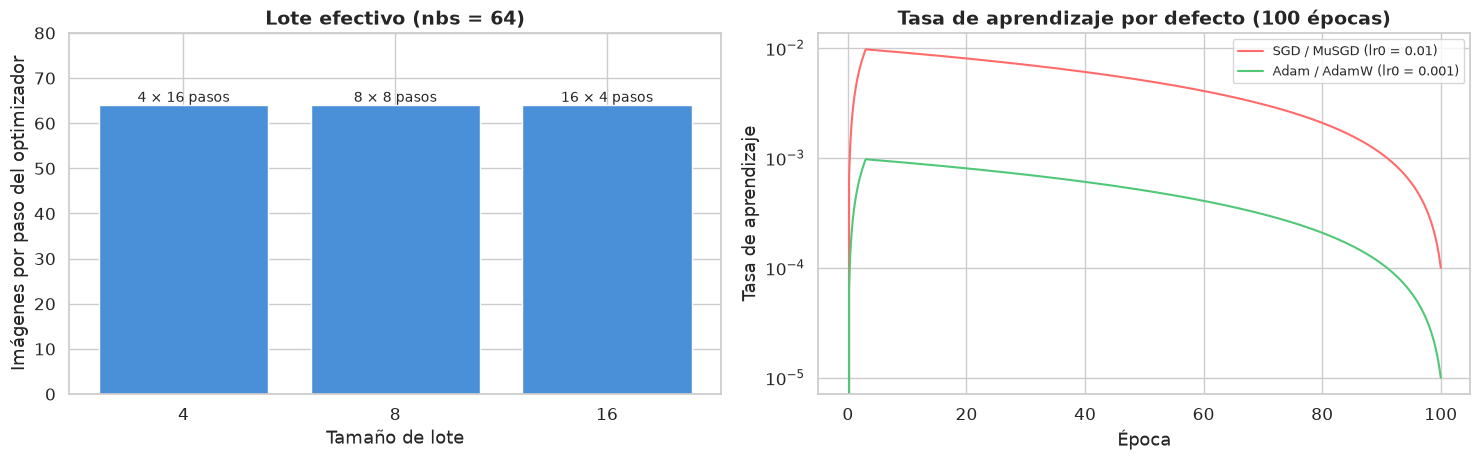

In [3]:
N_TRAIN = len(stems)
NBS = 64
iteraciones = int(np.ceil(N_TRAIN / NBS)) * 100              # como en el entrenador de Ultralytics, con 100 épocas
lr_auto = round(0.002 * 5 / (4 + 2), 6)                      # fórmula del modo 'auto' para 2 clases
print(f"optimizer='auto': {iteraciones} iteraciones (< 10 000) -> AdamW con lr0 = {lr_auto}; ignora el lr0 configurado")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8))
lotes = [4, 8, 16]
acum = [max(round(NBS / b), 1) for b in lotes]
barras = a1.bar([str(b) for b in lotes], [b * a for b, a in zip(lotes, acum)], color='#4A90D9')
a1.bar_label(barras, labels=[f'{b} × {a} pasos' for b, a in zip(lotes, acum)], fontsize=10)
a1.set_xlabel('Tamaño de lote'); a1.set_ylabel('Imágenes por paso del optimizador'); a1.set_ylim(0, 80)
a1.set_title('Lote efectivo (nbs = 64)')
ep = np.linspace(0, 100, 501)
for nombre, lr0, color in (('SGD / MuSGD (lr0 = 0.01)', 0.01, '#FF6B6B'), ('Adam / AdamW (lr0 = 0.001)', 0.001, '#50C878')):
    lineal = ((1 - ep / 100) * (1 - 0.01) + 0.01) * lr0
    a2.plot(ep, np.where(ep < 3, lineal * ep / 3, lineal), color=color, label=nombre)
a2.set_yscale('log'); a2.set_xlabel('Época'); a2.set_ylabel('Tasa de aprendizaje')
a2.set_title('Tasa de aprendizaje por defecto (100 épocas)'); a2.legend(fontsize=9)
C.guardar(SALIDA, 'evidencia_optimizacion.png')

**Lectura:**
- **El modo `'auto'`**, que los artículos llaman "valores por defecto", elige AdamW con lr0 ≈ 0.0017 en este dataset e ignora el `lr0` configurado. Por eso el optimizador se compara explícitamente en la 2.2, cada uno con su tasa estándar.
- **Con `nbs = 64`**, el entrenador acumula gradientes hasta 64 imágenes con cualquier lote: 4 × 16, 8 × 8 o 16 × 4 pasos. El lote cambia sobre todo la velocidad, la memoria y las estadísticas de BatchNorm. Por eso **no se ajusta**: se usa el valor por defecto de Ultralytics, **16**, que cabe en la A100 (unos 23 GB con YOLOv11s a 1280 px).
- **El calendario por defecto** (calentamiento de 3 épocas y caída lineal hasta el 1 % de `lr0`) se mantiene. `momentum`, `weight_decay` y los parámetros de calentamiento son secundarios: cambiarlos multiplicaría el diseño sin una razón concreta.

## 2. Aumento nativo de Ultralytics

Ultralytics aplica el aumento **en línea**: transforma cada imagen en cada época del entrenamiento, sin generar copias en disco. Los aumentos se aplican en cadena, cada uno con su propia probabilidad:

| Paso | Transformación | Por defecto |
| :---: | :--- | :--- |
| 1 | Mosaico (`mosaic`) | 1.0, salvo las últimas 10 épocas (`close_mosaic`) |
| 2 | Escala y traslación (`scale`, `translate`); giro, cizalla y perspectiva (`degrees`, `shear`, `perspective`) | 0.5 y 0.1; los otros tres en 0 |
| 3 | `mixup` y `cutmix` | 0 |
| 4 | Albumentations (`augmentations`) | `Blur`, `MedianBlur`, `ToGray` y `CLAHE`, con p = 0.01 (ver `2.1_aumento_datos.ipynb`) |
| 5 | HSV (`hsv_h`, `hsv_s`, `hsv_v`) | 0.015, 0.7 y 0.4 |
| 6 | Volteo vertical (`flipud`) | 0 |
| 7 | Volteo horizontal (`fliplr`) | 0.5 |

### 2.1. Aumento por defecto

Así ve el modelo las imágenes de entrenamiento con el aumento por defecto:

Fast image access ✅ (ping: 0.0±0.0 ms, read: 7049.4±420.8 MB/s, size: 283.6 KB)


Scanning /tmp/tmpi8dgvpoa/labels... 29 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29 3.5Kit/s 0.0s

New cache created: /tmp/tmpi8dgvpoa/labels.cache


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


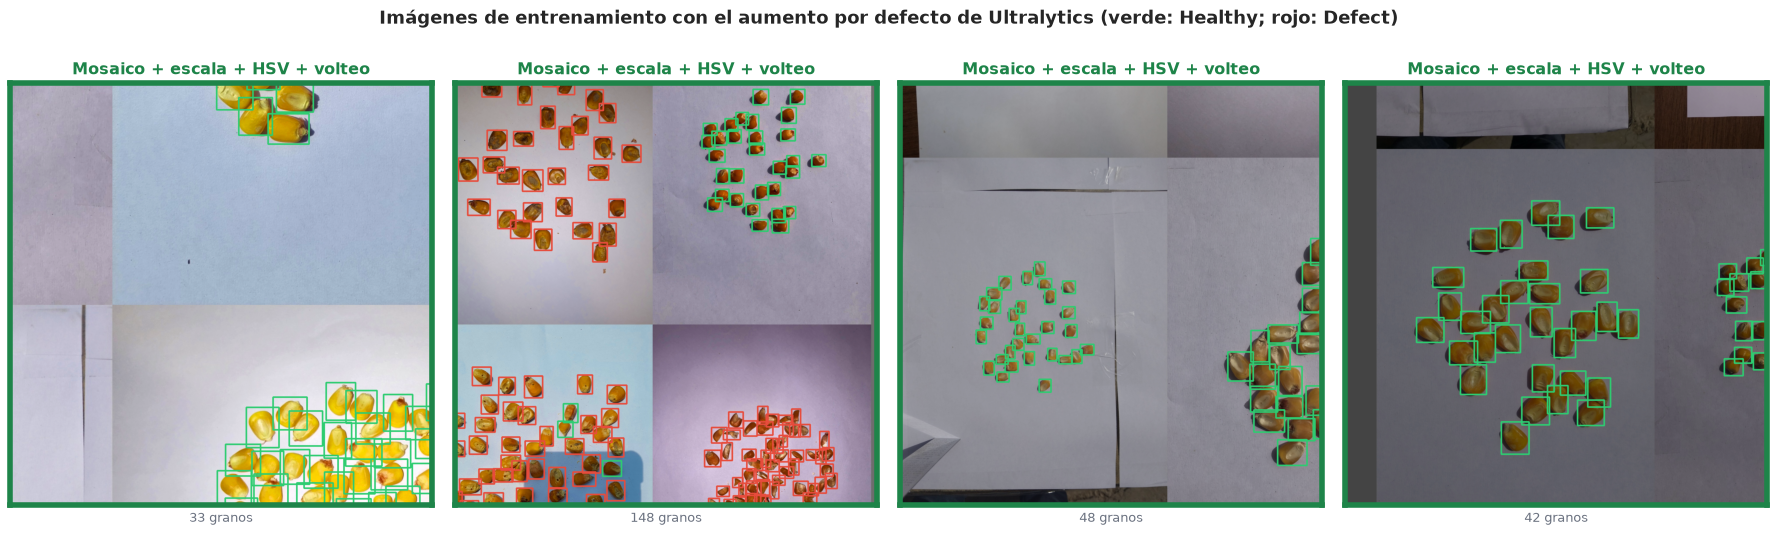

In [4]:
# Así ve el modelo las imágenes de entrenamiento con el aumento por defecto (flujo real de Ultralytics)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (img, n) in zip(axes, ejemplos_ultralytics(get_cfg())):
    mostrar(ax, img, 'Mosaico + escala + HSV + volteo', f'{n} granos', 'ok')
fig.suptitle('Imágenes de entrenamiento con el aumento por defecto de Ultralytics (verde: Healthy; rojo: Defect)', fontsize=13, fontweight='bold', y=1.03)
C.guardar(SALIDA, 'evidencia_aumento_por_defecto.png')

### 2.2. Color

En este dataset el color es una señal diagnóstica: `Fungus` se distingue por manchas oscuras o verdosas, y `Damage` y `Shriveled`, por cambios de tono. En el OE1, la normalización fotométrica, que altera el color, redujo la precisión. Se comparan `bgr` y los extremos del aumento HSV por defecto sobre granos de cuatro subtipos, cada uno de un lote distinto.

In [5]:
grupo('Aumento: color', [
    ('hsv_h', '0.015', 'Por defecto: escala el tono solo un ±1.5 %'),
    ('hsv_s', '0.7', 'Por defecto: variación de saturación entre cámaras'),
    ('hsv_v', '0.4', 'Por defecto: variación de brillo por iluminación'),
    ('bgr', '0.0', 'Desactivado: vuelve azul el grano'),
])

,por defecto,en el OE2,decisión
parámetro,,,
hsv_h,0.015,0.015,Por defecto: escala el tono solo un ±1.5 %
hsv_s,0.7,0.7,Por defecto: variación de saturación entre cám...
hsv_v,0.4,0.4,Por defecto: variación de brillo por iluminación
bgr,0.0,0.0,Desactivado: vuelve azul el grano


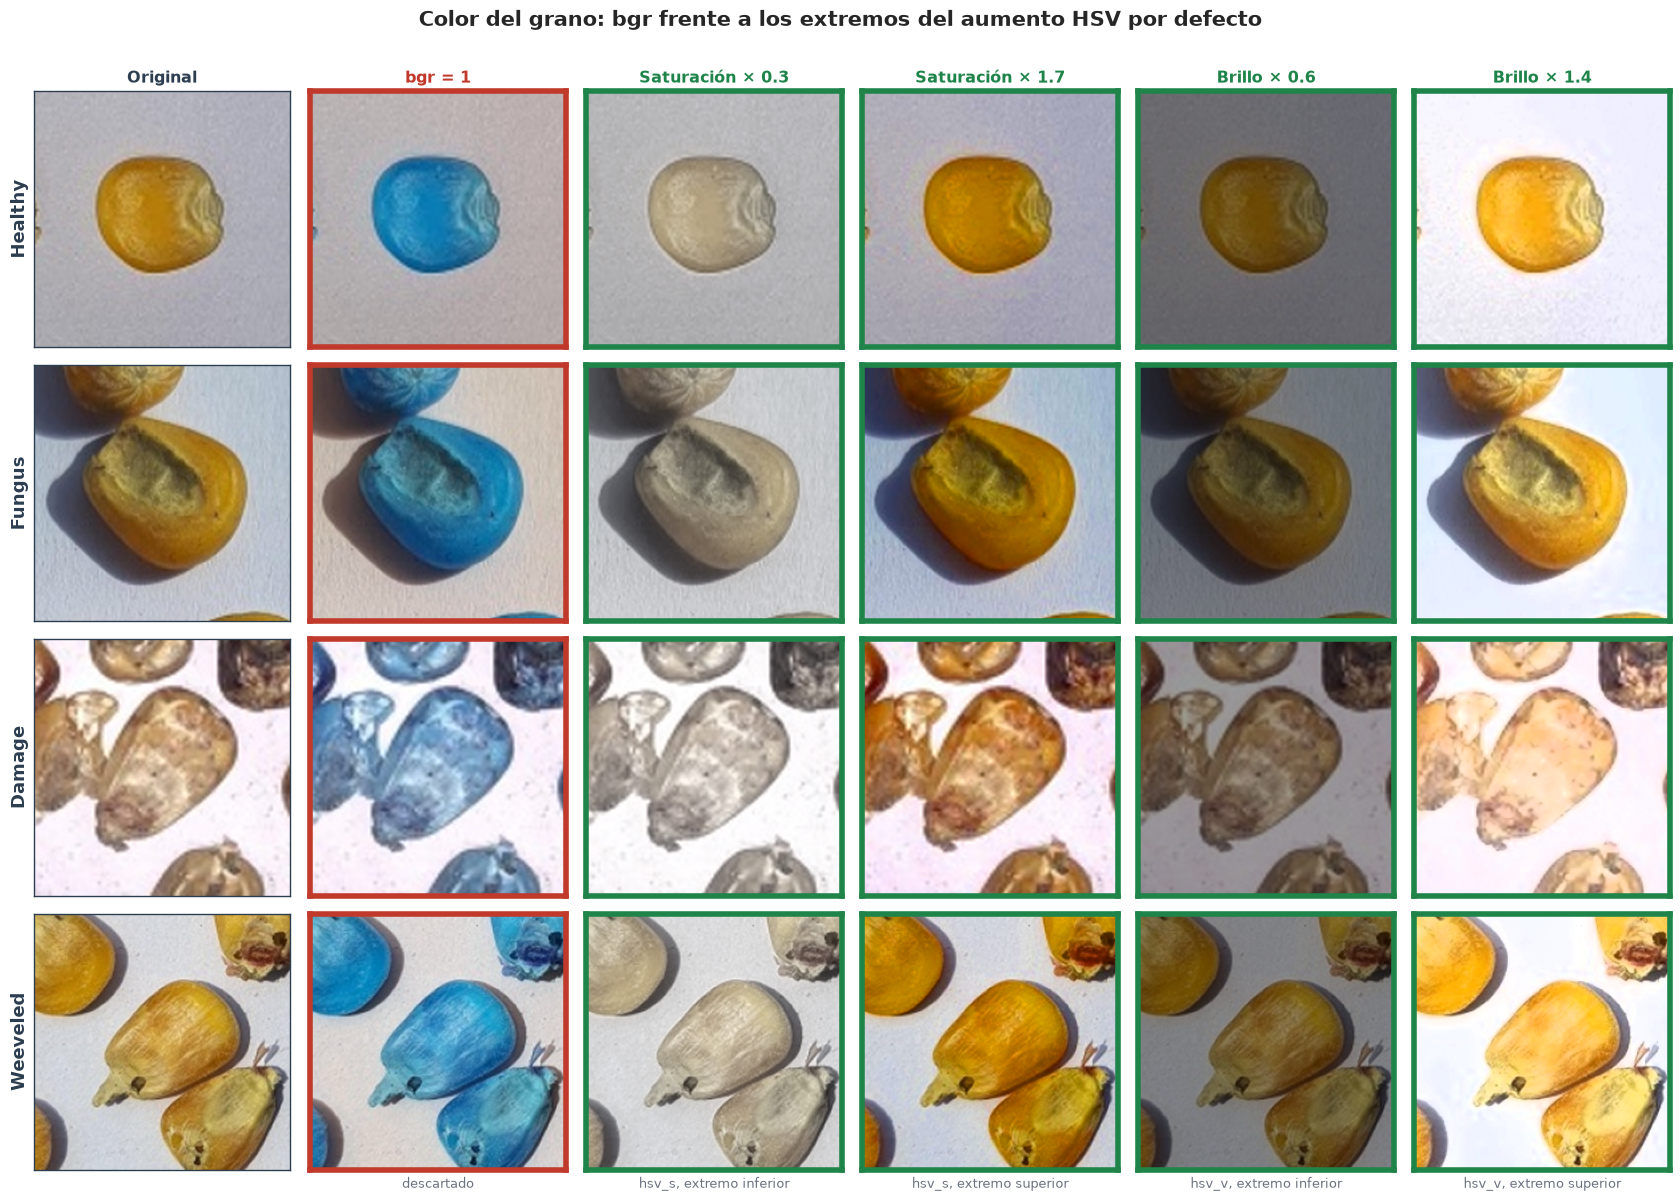

In [6]:
columnas = [('Original', lambda g: g, None, None),
            ('bgr = 1', lambda g: g[..., ::-1].copy(), 'mal', 'descartado'),
            ('Saturación × 0.3', lambda g: hsv(g, s=0.3), 'ok', 'hsv_s, extremo inferior'),
            ('Saturación × 1.7', lambda g: hsv(g, s=1.7), 'ok', 'hsv_s, extremo superior'),
            ('Brillo × 0.6', lambda g: hsv(g, v=0.6), 'ok', 'hsv_v, extremo inferior'),
            ('Brillo × 1.4', lambda g: hsv(g, v=1.4), 'ok', 'hsv_v, extremo superior')]
filas = [3, 2, 1, 9]
fig, axes = plt.subplots(len(filas), len(columnas), figsize=(17, 12))
for i, st in enumerate(filas):
    g, _, _ = grano(st, k=i)
    for j, (titulo, f, estado, nota) in enumerate(columnas):
        mostrar(axes[i, j], f(g), titulo if i == 0 else '', nota if i == len(filas) - 1 else None, estado)
    axes[i, 0].set_ylabel(NOMBRE[st], fontsize=13, fontweight='bold', color=NEUTRO)
fig.suptitle('Color del grano: bgr frente a los extremos del aumento HSV por defecto', fontsize=15, fontweight='bold', y=1.0)
C.guardar(SALIDA, 'evidencia_color.png')

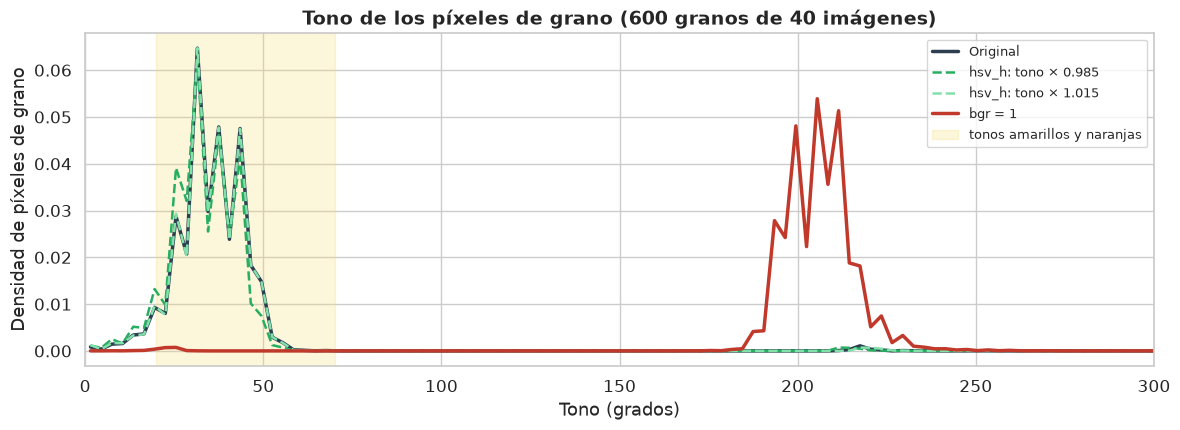

In [7]:
# Distribución del tono de los píxeles de grano (saturación > 60, para excluir el fondo blanco)
def tonos(img):
    x = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    return x[..., 0][x[..., 1] > 60].astype(float) * 2   # grados
rng = np.random.default_rng(0)
muestra = rng.choice(stems, 40, replace=False)
variantes = {'Original': lambda g: g, 'hsv_h: tono × 0.985': lambda g: hsv(g, h=0.985),
             'hsv_h: tono × 1.015': lambda g: hsv(g, h=1.015), 'bgr = 1': lambda g: g[..., ::-1].copy()}
colores = {'Original': NEUTRO, 'hsv_h: tono × 0.985': '#27AE60', 'hsv_h: tono × 1.015': '#82E0AA', 'bgr = 1': MAL}
datos = {k: [] for k in variantes}
for s in muestra:
    img, xyxy, _, _ = cargar(s)
    for x1, y1, x2, y2 in xyxy.astype(int)[:15]:
        g = img[y1:y2, x1:x2]
        for k, f in variantes.items():
            datos[k].append(tonos(f(g)))
fig, ax = plt.subplots(figsize=(12, 4.5))
bins = np.arange(0, 361, 3)
for k, v in datos.items():
    h, _ = np.histogram(np.concatenate(v), bins=bins, density=True)
    ax.plot(bins[:-1] + 1.5, h, color=colores[k], lw=2.5 if k in ('Original', 'bgr = 1') else 1.8,
            ls='--' if 'hsv_h' in k else '-', label=k)
ax.axvspan(20, 70, color='#F7DC6F', alpha=0.25, label='tonos amarillos y naranjas')
ax.set_xlim(0, 300); ax.set_xlabel('Tono (grados)'); ax.set_ylabel('Densidad de píxeles de grano')
ax.set_title(f'Tono de los píxeles de grano ({len(datos["Original"])} granos de {len(muestra)} imágenes)')
ax.legend(fontsize=9.5)
C.guardar(SALIDA, 'evidencia_tono.png')

**Lectura:**
- **`bgr`** lleva el grano de los tonos amarillos y naranjas a tonos azules, que no existen en el maíz, y cambia el color de las manchas de hongo. Se desactiva.
- **`hsv_h`** desplaza la distribución del tono de forma casi imperceptible: las curvas se superponen con la original.
- **`hsv_s` y `hsv_v`** simulan cámaras más o menos saturadas y fotos más oscuras o claras, sin cambiar el tono ni las manchas. Son variaciones reales entre capturas; este aumento por defecto mejoró el modelo en el OE1.

### 2.3. Geometría

Cuando Ultralytics gira o deforma una imagen (`degrees`, `shear`, `perspective`), transforma las 4 esquinas de cada caja y toma el rectángulo que las contiene. Ese rectángulo es mayor que el grano girado, porque el grano, más parecido a una elipse, no llena las esquinas. Se mide en **todas las cajas de entrenamiento** el IoU máximo entre la caja de Ultralytics y la caja ajustada al grano transformado (la elipse inscrita en su caja original). Ambas cajas comparten centro y una contiene a la otra, así que el IoU es el cociente de sus áreas y tiene fórmula cerrada para cualquier ángulo.

In [8]:
grupo('Aumento: geometría', [
    ('fliplr', '0.5', 'Por defecto: volteo horizontal exacto'),
    ('flipud', '0.0 / 0.5', 'Se ajusta en la 2.2, junto con RandomRotate90: transformaciones exactas'),
    ('translate', '0.1', 'Por defecto'),
    ('scale', '0.5', 'Por defecto: simula distintas distancias de captura'),
    ('degrees', '0.0', 'Desactivado: cajas holgadas'),
    ('shear', '0.0', 'Desactivado: cajas holgadas'),
    ('perspective', '0.0', 'Desactivado: cajas holgadas; cámara cenital fija'),
])

,por defecto,en el OE2,decisión
parámetro,,,
fliplr,0.5,0.5,Por defecto: volteo horizontal exacto
flipud,0.0,0.0 / 0.5,"Se ajusta en la 2.2, junto con RandomRotate90:..."
translate,0.1,0.1,Por defecto
scale,0.5,0.5,Por defecto: simula distintas distancias de ca...
degrees,0.0,0.0,Desactivado: cajas holgadas
shear,0.0,0.0,Desactivado: cajas holgadas
perspective,0.0,0.0,Desactivado: cajas holgadas; cámara cenital fija


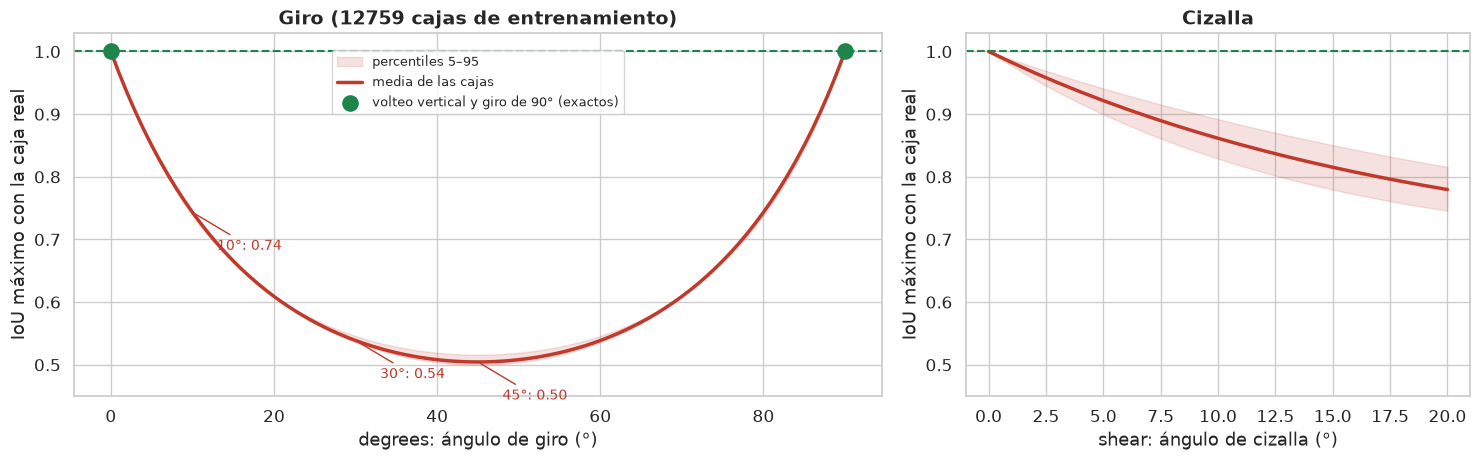

,IoU máximo (media)
degrees = 10,0.743
degrees = 30,0.539
degrees = 45,0.504
shear = 5,0.922
shear = 10,0.861
flipud,1.000
RandomRotate90,1.000


In [9]:
cajas = []
for st in stems:
    _, x, _, _ = cargar(st)
    cajas.append(np.stack([x[:, 2] - x[:, 0], x[:, 3] - x[:, 1]], 1))
w, h = np.concatenate(cajas).T
a, b = w / 2, h / 2

def iou_giro(g):
    c, s = abs(np.cos(np.radians(g))), abs(np.sin(np.radians(g)))
    ult = (w * c + h * s) * (w * s + h * c)                                                # rectángulo girado
    real = 4 * np.sqrt(a**2 * c**2 + b**2 * s**2) * np.sqrt(a**2 * s**2 + b**2 * c**2)    # elipse girada
    return real / ult

def iou_cizalla(g):
    t = abs(np.tan(np.radians(g)))
    return 2 * np.sqrt(a**2 + (t * b)**2) / (w + h * t)

angulos, cizallas = np.arange(0, 91, 1), np.arange(0, 21, 1)
G = np.array([iou_giro(g) for g in angulos]); S = np.array([iou_cizalla(g) for g in cizallas])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
for ax, x, Y, nombre in ((a1, angulos, G, 'degrees: ángulo de giro (°)'), (a2, cizallas, S, 'shear: ángulo de cizalla (°)')):
    ax.fill_between(x, np.percentile(Y, 5, 1), np.percentile(Y, 95, 1), color=MAL, alpha=0.15, label='percentiles 5–95')
    ax.plot(x, Y.mean(1), color=MAL, lw=2.5, label='media de las cajas')
    ax.axhline(1, color=OK, ls='--', lw=1.5); ax.set_ylim(0.45, 1.03)
    ax.set_xlabel(nombre); ax.set_ylabel('IoU máximo con la caja real')
a1.scatter([0, 90], [1, 1], s=120, color=OK, zorder=5, label='volteo vertical y giro de 90° (exactos)')
for g in (10, 30, 45):
    a1.annotate(f'{g}°: {G[g].mean():.2f}', (g, G[g].mean()), xytext=(g + 3, G[g].mean() - 0.06), fontsize=10, color=MAL,
                arrowprops=dict(arrowstyle='-', color=MAL))
a1.set_title(f'Giro ({len(w)} cajas de entrenamiento)'); a2.set_title('Cizalla'); a1.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, 0.97))
C.guardar(SALIDA, 'evidencia_iou_giro.png')
pd.DataFrame({'IoU máximo (media)': [G[10].mean(), G[30].mean(), G[45].mean(), S[5].mean(), S[10].mean(), 1.0, 1.0]},
             index=['degrees = 10', 'degrees = 30', 'degrees = 45', 'shear = 5', 'shear = 10', 'flipud', 'RandomRotate90']).round(3)

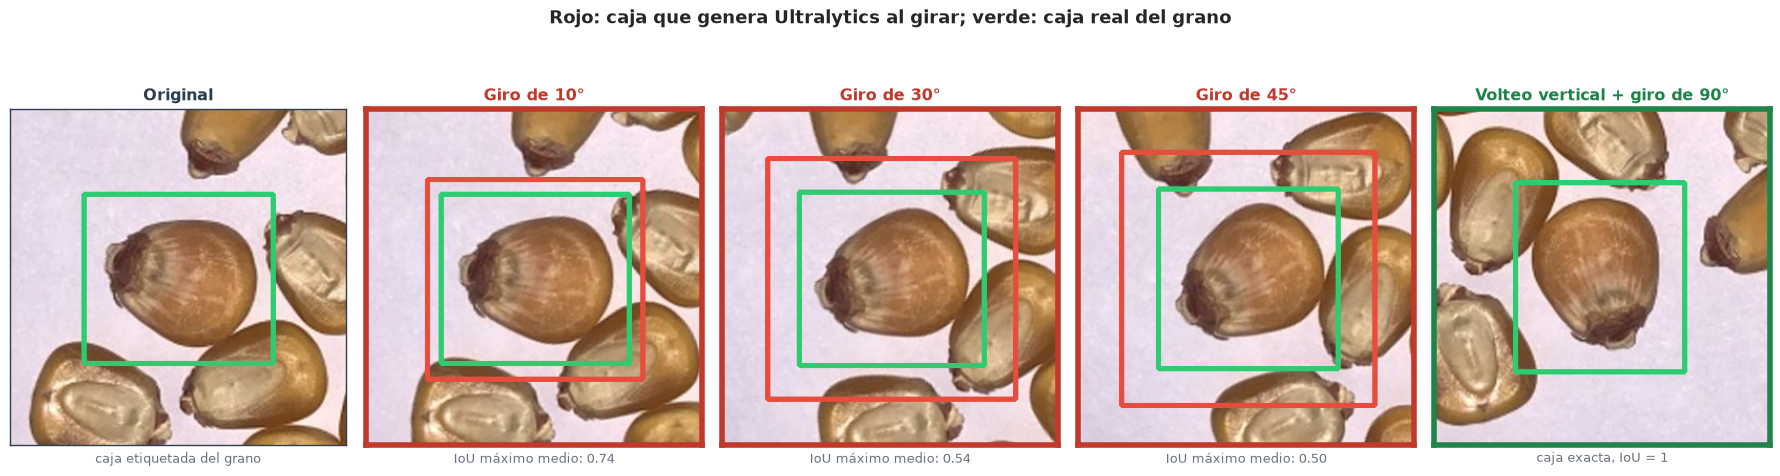

In [10]:
# Recorte amplio (3 veces el grano) para que al girar no aparezcan bordes; se muestra la zona central
grande, _, caja = grano(3, k=2, lado=540, margen=3.0)
def girar(grados):
    Mt = cv2.getRotationMatrix2D((270, 270), grados, 1.0)
    im = cv2.warpAffine(grande, Mt, (540, 540))
    x1, y1, x2, y2 = caja; t = np.linspace(0, 2 * np.pi, 360)
    esq = np.array([[x1, y1, 1], [x2, y1, 1], [x2, y2, 1], [x1, y2, 1]]) @ Mt.T
    eli = np.stack([(x1 + x2) / 2 + (x2 - x1) / 2 * np.cos(t), (y1 + y2) / 2 + (y2 - y1) / 2 * np.sin(t), np.ones_like(t)], 1) @ Mt.T
    im = dibujar(dibujar(im, [[*esq.min(0), *esq.max(0)]], CAJA_MAL, 3), [[*eli.min(0), *eli.max(0)]], CAJA_OK, 3)
    return im[110:430, 110:430]
exacta = np.rot90(grande[::-1]).copy()
x1, y1, x2, y2 = caja
caja_ex = [539 - y2, x1, 539 - y1, x2]   # volteo vertical y giro de 90° (antihorario) de la caja
paneles = [('Original', dibujar(grande, [caja], CAJA_OK, 3)[110:430, 110:430], None, 'caja etiquetada del grano')]
paneles += [(f'Giro de {gr}°', girar(gr), 'mal', f'IoU máximo medio: {G[gr].mean():.2f}') for gr in (10, 30, 45)]
paneles += [('Volteo vertical + giro de 90°', dibujar(exacta, [caja_ex], CAJA_OK, 3)[110:430, 110:430], 'ok', 'caja exacta, IoU = 1')]
fig, axes = plt.subplots(1, 5, figsize=(18, 4.6))
for ax, (t, im, est, n) in zip(axes, paneles):
    mostrar(ax, im, t, n, est)
fig.suptitle('Rojo: caja que genera Ultralytics al girar; verde: caja real del grano', fontsize=13, fontweight='bold', y=1.04)
C.guardar(SALIDA, 'evidencia_geometria.png')

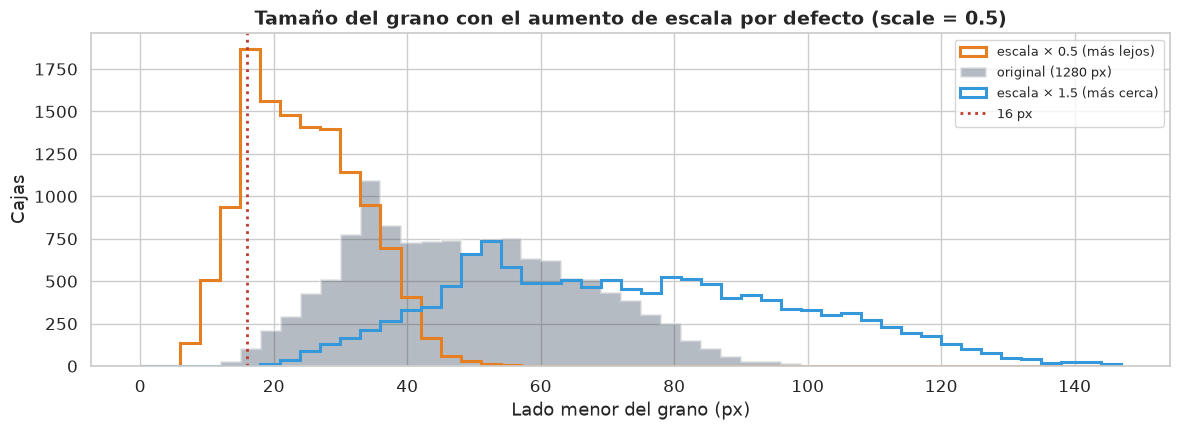

Lado menor mediano: 48 px; con escala × 0.5: 24 px; cajas por debajo de 16 px a × 0.5: 16.1 %


In [11]:
# scale = 0.5: cada imagen se reescala entre ×0.5 y ×1.5, como si se fotografiara más lejos o más cerca
lado = np.minimum(w, h)
fig, ax = plt.subplots(figsize=(12, 4.5))
bins = np.arange(0, 150, 3)
for f, color, nombre in ((0.5, '#E67E22', 'escala × 0.5 (más lejos)'), (1.0, NEUTRO, 'original (1280 px)'), (1.5, '#3498DB', 'escala × 1.5 (más cerca)')):
    ax.hist(lado * f, bins=bins, histtype='stepfilled' if f == 1 else 'step', lw=2.2, color=color, alpha=0.35 if f == 1 else 1, label=nombre)
ax.axvline(16, color=MAL, ls=':', lw=2, label='16 px')
ax.set_xlabel('Lado menor del grano (px)'); ax.set_ylabel('Cajas')
ax.set_title('Tamaño del grano con el aumento de escala por defecto (scale = 0.5)'); ax.legend(fontsize=9.5)
C.guardar(SALIDA, 'evidencia_escala.png')
print(f'Lado menor mediano: {np.median(lado):.0f} px; con escala × 0.5: {np.median(lado) * 0.5:.0f} px; '
      f'cajas por debajo de 16 px a × 0.5: {100 * (lado * 0.5 < 16).mean():.1f} %')

**Lectura:**
- **Giro y cizalla:** con un giro de solo 10°, el IoU máximo entre la caja de Ultralytics y la caja real del grano ya baja a 0.74; con 30°, a 0.54. Entrenar con esas cajas enseñaría a predecir cajas holgadas, justo lo que penaliza el mAP50-95. La cizalla tiene el mismo efecto, más lento. Se desactivan.
- **Volteo vertical y giros de 90°:** conservan el ajuste exacto (IoU = 1). En la vista cenital el grano no tiene "arriba", así que aportan diversidad real: se prueban en la 2.2 (configuración C). Por defecto no están activos (`flipud = 0.0`, `degrees = 0.0`).
- **Escala:** el aumento por defecto (`scale = 0.5`) simula fotos tomadas más lejos y más cerca. Así el modelo ve granos de tamaños variados, lo que ayuda frente a cambios en la distancia de captura. Se mantiene.

### 2.4. Composición de imágenes

- **`mosaic`** une 4 imágenes en una; es parte del aumento por defecto (sección 2.1).
- **`mixup`** superpone dos imágenes con una proporción ~Beta(32, 32), cercana al 50 %, y conserva las etiquetas de ambas.
- **`cutmix`** pega un rectángulo de otra imagen en una zona sin cajas y conserva las cajas de la segunda imagen que tengan al menos el 10 % de su área dentro del rectángulo, recortadas al borde.

`mixup` y `cutmix` se reproducen con las mismas reglas que Ultralytics (`ultralytics/data/augment.py`).

In [12]:
grupo('Aumento: composición de imágenes', [
    ('mosaic', '1.0', 'Por defecto: validado en el OE1 (+0.041 de mAP50-95 con el aumento por defecto)'),
    ('close_mosaic', '10', 'Por defecto: las últimas épocas, con imágenes completas como en la inferencia'),
    ('mixup', '0.0', 'Desactivado: granos semitransparentes'),
    ('cutmix', '0.0', 'Desactivado: granos recortados que conservan su etiqueta'),
    ('copy_paste', '0.0', 'No aplica: requiere polígonos (segmentación u OBB)'),
    ('copy_paste_mode', 'flip', 'No aplica: solo con copy_paste'),
])

,por defecto,en el OE2,decisión
parámetro,,,
mosaic,1.0,1.0,Por defecto: validado en el OE1 (+0.041 de mAP...
close_mosaic,10,10,"Por defecto: las últimas épocas, con imágenes ..."
mixup,0.0,0.0,Desactivado: granos semitransparentes
cutmix,0.0,0.0,Desactivado: granos recortados que conservan s...
copy_paste,0.0,0.0,No aplica: requiere polígonos (segmentación u ...
copy_paste_mode,flip,flip,No aplica: solo con copy_paste


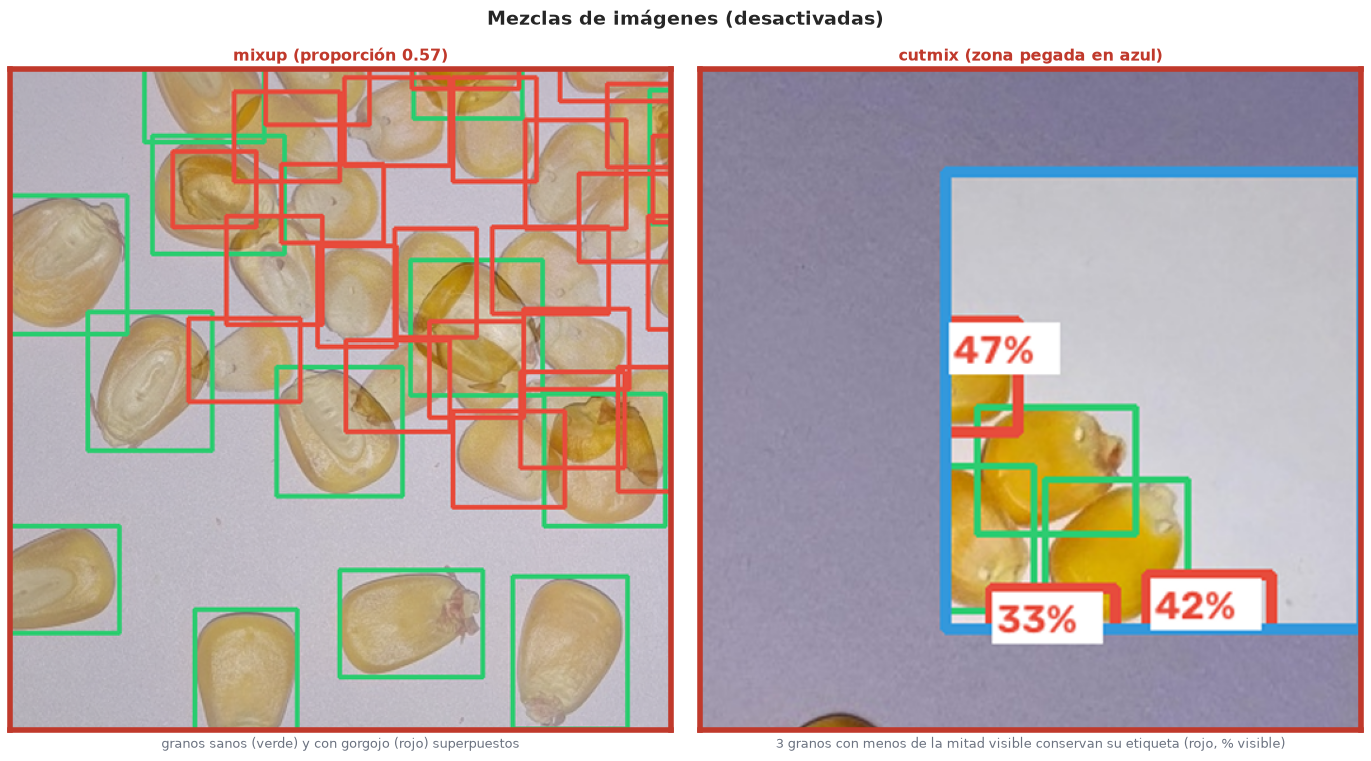

In [13]:
rng = np.random.default_rng(3)
stem_a = next(s for s in stems if list(SUBTIPOS[s]).count(3) > 20); stem_b = max(stems, key=lambda s: list(SUBTIPOS[s]).count(9))
ia, xa, _, _ = cargar(stem_a); ib, xb, _, _ = cargar(stem_b)
h_, w_ = min(ia.shape[0], ib.shape[0]), min(ia.shape[1], ib.shape[1])
ia, ib = ia[:h_, :w_], ib[:h_, :w_]
xa = xa[(xa[:, 2] <= w_) & (xa[:, 3] <= h_)]; xb = xb[(xb[:, 2] <= w_) & (xb[:, 3] <= h_)]

# mixup: proporción de Beta(32, 32), como en Ultralytics
r = rng.beta(32, 32)
mezcla = dibujar(dibujar((ia * r + ib * (1 - r)).astype(np.uint8), xa, CAJA_OK, 2), xb, CAJA_MAL, 2)
centro = ((xa[:, 0] + xa[:, 2]) / 2).mean(), ((xa[:, 1] + xa[:, 3]) / 2).mean()
mx, _ = recorte(mezcla, centro, 420, 520)

# cutmix: rectángulo sin cajas en A; cajas de B con ≥ 10 % de su área dentro, recortadas al borde
def ioa(area, cajas):
    ix = np.clip(np.minimum(area[2], cajas[:, 2]) - np.maximum(area[0], cajas[:, 0]), 0, None)
    iy = np.clip(np.minimum(area[3], cajas[:, 3]) - np.maximum(area[1], cajas[:, 1]), 0, None)
    return ix * iy / ((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1]))
for _ in range(50000):
    lam = rng.beta(1.0, 1.0); cw, ch = int(w_ * np.sqrt(1 - lam)), int(h_ * np.sqrt(1 - lam))
    cx, cy = rng.integers(w_), rng.integers(h_)
    area = np.array([np.clip(cx - cw // 2, 0, w_), np.clip(cy - ch // 2, 0, h_), np.clip(cx + cw // 2, 0, w_), np.clip(cy + ch // 2, 0, h_)])
    f = ioa(area, xb)
    if ioa(area, xa).sum() == 0 and ((f >= 0.25) & (f < 0.5)).sum() >= 3 and max(area[2] - area[0], area[3] - area[1]) < 520:
        break
cut = ia.copy(); cut[area[1]:area[3], area[0]:area[2]] = ib[area[1]:area[3], area[0]:area[2]]
fv = ioa(area, xb); k = fv >= 0.1
rec = np.column_stack([np.maximum(xb[k, 0], area[0]), np.maximum(xb[k, 1], area[1]), np.minimum(xb[k, 2], area[2]), np.minimum(xb[k, 3], area[3])])
parcial = fv[k] < 0.5
vista = dibujar(dibujar(cut, rec[~parcial], CAJA_OK, 2), rec[parcial], CAJA_MAL, 3)
cv2.rectangle(vista, tuple(int(v) for v in area[:2]), tuple(int(v) for v in area[2:]), CAJA_B, 4)
rp = rec[parcial]
for (x1, y1, x2, y2), p in zip(rp, fv[k][parcial]):
    cv2.rectangle(vista, (int(x1) + 2, int(y1) + 2), (int(x1) + 50, int(y1) + 24), (255, 255, 255), -1)
    cv2.putText(vista, f'{100 * p:.0f}%', (int(x1) + 4, int(y1) + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, CAJA_MAL, 2)
lado_c = int(max(area[2] - area[0], area[3] - area[1]) + 90)
cm, _ = recorte(vista, ((area[0] + area[2]) / 2, (area[1] + area[3]) / 2), lado_c, 520)

fig, axes = plt.subplots(1, 2, figsize=(14, 7.4))
mostrar(axes[0], mx, f'mixup (proporción {r:.2f})', 'granos sanos (verde) y con gorgojo (rojo) superpuestos', 'mal')
mostrar(axes[1], cm, 'cutmix (zona pegada en azul)', f'{parcial.sum()} granos con menos de la mitad visible conservan su etiqueta (rojo, % visible)', 'mal')
fig.suptitle('Mezclas de imágenes (desactivadas)', fontsize=14, fontweight='bold', y=1.0)
C.guardar(SALIDA, 'evidencia_mezclas.png')

**Lectura:**
- **`mixup`** produce granos semitransparentes con dos etiquetas superpuestas. Los defectos superficiales (orificios, manchas) quedan a medias y la etiqueta no corresponde a lo visible: es la contradicción que se corrigió en la limpieza del OE1.
- **`cutmix`** conserva granos de los que solo se ve una parte. Un grano `Defect` cuyo defecto quedó fuera del recorte sigue etiquetado como defectuoso.

### 2.5. Albumentations

Las transformaciones de Albumentations (las 4 que Ultralytics aplica por defecto y el conjunto propio que se agrega) se analizan en `2.1_aumento_datos.ipynb`.

In [14]:
grupo('Aumento: Albumentations', [
    ('augmentations', 'por defecto / conjunto propio', 'Se ajusta en la 2.2: el conjunto propio reemplaza a Blur, MedianBlur, ToGray y CLAHE'),
])

,por defecto,en el OE2,decisión
parámetro,,,
augmentations,None (API de Python),por defecto / conjunto propio,Se ajusta en la 2.2: el conjunto propio reempl...


## 3. Pérdida y clases

In [15]:
grupo('Pérdida y clases', [
    ('box', '7.5', 'Por defecto: pesos equilibrados de la pérdida; pueden ajustarse si el modelo falla en localizar o clasificar'),
    ('cls', '0.5', 'Por defecto'), ('dfl', '1.5', 'Por defecto'),
    ('cls_pw', '0.0', 'Desactivado: clases casi equilibradas'),
])

,por defecto,en el OE2,decisión
parámetro,,,
box,7.5,7.5,Por defecto: pesos equilibrados de la pérdida;...
cls,0.5,0.5,Por defecto
dfl,1.5,1.5,Por defecto
cls_pw,0.0,0.0,Desactivado: clases casi equilibradas


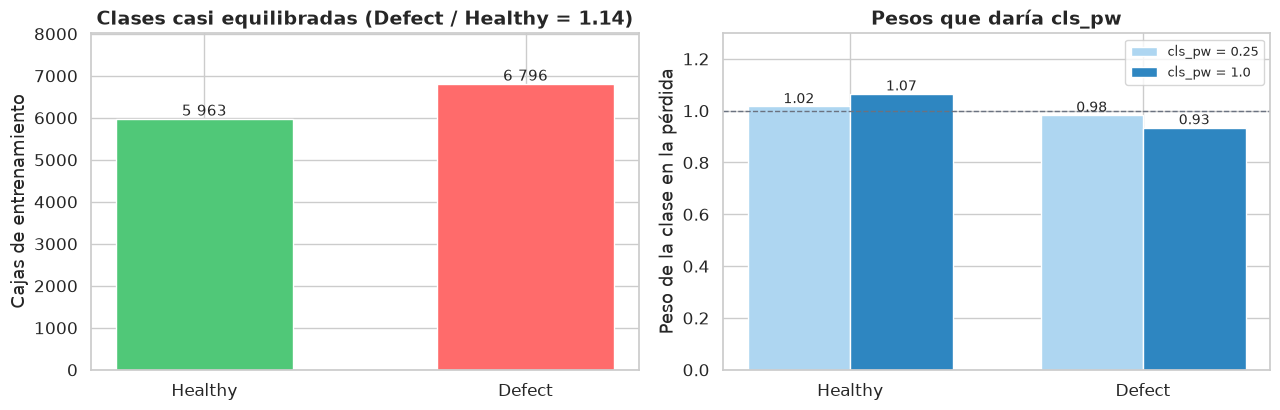

In [16]:
conteo = Counter()
for f in (FINAL / 'train' / 'labels').glob('*.txt'):
    conteo.update(C.leer_yolo(f)[1])
n = np.array([conteo[0], conteo[1]], dtype=float)
pesos = {pw: (lambda q: q / q.mean())((1 / n) ** pw) for pw in (0.25, 1.0)}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.3))
barras = a1.bar(C.CLASES_BINARIAS, n, color=[C.COLOR_BINARIO[c] for c in C.CLASES_BINARIAS], width=0.55)
a1.bar_label(barras, labels=[f'{int(v):,}'.replace(',', ' ') for v in n], fontsize=11); a1.set_ylim(0, n.max() * 1.18)
a1.set_ylabel('Cajas de entrenamiento'); a1.set_title(f'Clases casi equilibradas (Defect / Healthy = {n[1] / n[0]:.2f})')
x = np.arange(2)
for k, (pw, p) in enumerate(pesos.items()):
    bb = a2.bar(x + (k - 0.5) * 0.35, p, 0.35, label=f'cls_pw = {pw}', color=['#AED6F1', '#2E86C1'][k])
    a2.bar_label(bb, fmt='%.2f', fontsize=10)
a2.axhline(1, color=GRIS, ls='--', lw=1); a2.set_xticks(x); a2.set_xticklabels(C.CLASES_BINARIAS); a2.set_ylim(0, 1.3)
a2.set_ylabel('Peso de la clase en la pérdida'); a2.set_title('Pesos que daría cls_pw'); a2.legend(fontsize=9.5)
C.guardar(SALIDA, 'evidencia_clases.png')

**Lectura:** incluso con el peso completo (`cls_pw = 1`), los pesos de las dos clases quedan cerca de 1 (1.07 y 0.94). Con clases casi equilibradas, ponderarlas no aporta; el balanceo tampoco tuvo efecto en el OE1.

**Pesos de la pérdida (`box`, `cls`, `dfl`).** Se mantienen en 7.5, 0.5 y 1.5. Son valores equilibrados entre las tres partes de la pérdida: la regresión de la caja (`box`), la clasificación (`cls`) y la distribución de los bordes (`dfl`). Alterarlos cambia ese equilibrio y podría afectar a los resultados. Si el modelo se comporta mal en la detección o en la clasificación, pueden ajustarse en el futuro.

## 4. Validación y NMS

In [17]:
grupo('Validación y NMS', [
    ('val', 'True', 'Por defecto: validación en cada época para elegir best.pt'),
    ('split', 'val', 'Por defecto: el test se reserva para la 2.3'),
    ('conf', 'None (0.001 al validar)', 'Por defecto: el mAP usa todas las detecciones; el umbral de conteo se fija en la 2.2'),
    ('iou', '0.7', 'Por defecto: umbral de NMS'),
    ('max_det', '300', 'Por defecto: muy por encima del máximo de granos por imagen'),
])

,por defecto,en el OE2,decisión
parámetro,,,
val,True,True,Por defecto: validación en cada época para ele...
split,val,val,Por defecto: el test se reserva para la 2.3
conf,None,None (0.001 al validar),Por defecto: el mAP usa todas las detecciones;...
iou,0.7,0.7,Por defecto: umbral de NMS
max_det,300,300,Por defecto: muy por encima del máximo de gran...


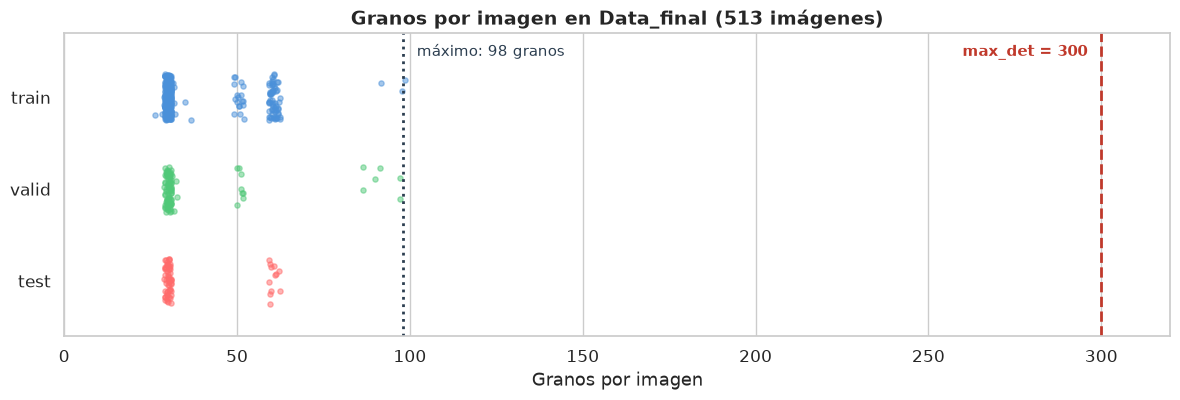

In [18]:
granos_img = pd.DataFrame([{'split': sp, 'granos': len(C.leer_yolo(f)[0])} for sp in C.SPLITS_FINALES for f in (FINAL / sp / 'labels').glob('*.txt')])
fig, ax = plt.subplots(figsize=(12, 4.2))
for sp, y in zip(C.SPLITS_FINALES, (2, 1, 0)):
    v = granos_img.query('split == @sp').granos
    ax.scatter(v + np.random.default_rng(0).uniform(-1, 1, len(v)), y + np.random.default_rng(1).uniform(-0.25, 0.25, len(v)),
               s=14, alpha=0.5, color=C.COLOR_SPLIT[sp], label=f'{sp} ({len(v)} imágenes)')
ax.axvline(300, color=MAL, ls='--', lw=2); ax.text(296, 2.45, 'max_det = 300', color=MAL, ha='right', fontsize=10.5, fontweight='bold')
mx = granos_img.granos.max()
ax.axvline(mx, color=NEUTRO, ls=':', lw=2); ax.text(mx + 4, 2.45, f'máximo: {mx} granos', color=NEUTRO, fontsize=10.5)
ax.set_yticks([2, 1, 0]); ax.set_yticklabels(C.SPLITS_FINALES); ax.set_xlim(0, 320); ax.set_ylim(-0.6, 2.7)
ax.set_xlabel('Granos por imagen'); ax.set_title(f'Granos por imagen en Data_final ({len(granos_img)} imágenes)'); ax.grid(axis='y', visible=False)
C.guardar(SALIDA, 'evidencia_max_det.png')

**Lectura:** el máximo de granos por imagen está muy por debajo de 300, así que `max_det` no limita el conteo.

## 5. Modelo y transferencia de aprendizaje

In [19]:
grupo('Modelo y transferencia', [
    ('model', 'yolo11n.pt, yolo11s.pt', 'Fijado: los dos modelos que compara el OE2'),
    ('pretrained', 'True', 'Fijado: transferencia de aprendizaje desde COCO'),
    ('freeze', 'None', 'Desactivado: se afinan todas las capas; los granos están lejos de las clases de COCO'),
    ('imgsz', '1280', 'Fijado: resolución elegida en el OE1'),
    ('multi_scale', '0.0', 'Desactivado: cambia la resolución de cada lote, con más memoria; scale ya varía el tamaño del grano'),
    ('single_cls', 'False', 'Por defecto: con una sola clase se perdería la distinción sano / defectuoso'),
    ('cls_remap', 'True', 'Por defecto: sin efecto, las clases no coinciden con las de COCO'),
    ('rect', 'False', 'Por defecto: lotes rectangulares, incompatibles con el mosaico'),
    ('fraction', '1.0', 'Por defecto: todo el conjunto de entrenamiento'),
])

,por defecto,en el OE2,decisión
parámetro,,,
model,None,"yolo11n.pt, yolo11s.pt",Fijado: los dos modelos que compara el OE2
pretrained,True,True,Fijado: transferencia de aprendizaje desde COCO
freeze,None,None,Desactivado: se afinan todas las capas; los gr...
imgsz,640,1280,Fijado: resolución elegida en el OE1
multi_scale,0.0,0.0,Desactivado: cambia la resolución de cada lote...
single_cls,False,False,Por defecto: con una sola clase se perdería la...
cls_remap,True,True,"Por defecto: sin efecto, las clases no coincid..."
rect,False,False,"Por defecto: lotes rectangulares, incompatible..."
fraction,1.0,1.0,Por defecto: todo el conjunto de entrenamiento


No se entrena desde cero, porque el dataset es pequeño (345 imágenes de entrenamiento), ni se congela el backbone: se afinan todas las capas desde los pesos de COCO para que se adapten a los granos de maíz.

## 6. Configuración de ejecución y parámetros que no aplican

**Configuración de ejecución.** No cambian lo que aprende el modelo; se fijan iguales para todas las corridas:
- **Datos y organización:** `data`, `project`, `name`, `exist_ok`, `save`, `save_period`, `plots`, `verbose`, `save_json`.
- **Reproducibilidad:** `seed` (42; 7 y 28 en el entrenamiento final) y `deterministic`.
- **Rendimiento:** `device`, `workers`, `cache`, `amp`, `compile`, `channels_last`, `profile`, `time`, `resume`.
- **Inferencia y exportación:** `quantize`, `dnn` y `nms`.
- **Destilación (no se usa):** `distill_model` y `dis`.

**No aplican a la detección con cajas:** `overlap_mask` y `mask_ratio` (segmentación), `pose`, `kobj` y `rle` (pose), `angle` (OBB), `dlog`, `dgrad` y `dlam` (profundidad), y `auto_augment`, `erasing` y `dropout` (clasificación).

In [20]:
CONFIGURACION = ['data', 'project', 'name', 'exist_ok', 'save', 'save_period', 'plots', 'verbose', 'save_json', 'seed', 'deterministic',
                 'device', 'workers', 'cache', 'amp', 'compile', 'channels_last', 'profile', 'time', 'resume', 'quantize', 'dnn', 'nms',
                 'distill_model', 'dis']
NO_APLICAN = ['overlap_mask', 'mask_ratio', 'pose', 'kobj', 'rle', 'angle', 'dlog', 'dgrad', 'dlam', 'auto_augment', 'erasing', 'dropout']
REVISADOS.update({p: 'Configuración de ejecución' for p in CONFIGURACION})
REVISADOS.update({p: 'No aplica' for p in NO_APLICAN})
faltan = sorted(set(DEFECTO) - set(REVISADOS))
assert not faltan, f'Parámetros sin revisar: {faltan}'
print(f'{len(DEFECTO)} parámetros revisados (85 de default.yaml + augmentations); ninguno sin clasificar.')
pd.Series(REVISADOS).value_counts().rename('parámetros').to_frame()

86 parámetros revisados (85 de default.yaml + augmentations); ninguno sin clasificar.


,parámetros
Configuración de ejecución,25
Optimización,13
No aplica,12
Modelo y transferencia,9
Aumento: geometría,7
Aumento: composición de imágenes,6
Validación y NMS,5
Aumento: color,4
Pérdida y clases,4
Aumento: Albumentations,1


## 7. Resumen

| Decisión | Parámetros |
| :--- | :--- |
| **Se ajustan en la 2.2** | `optimizer`, `lr0`, `augmentations` (conjunto propio de Albumentations), `flipud` con `RandomRotate90` |
| **Desactivados con evidencia** | `bgr` (color), `degrees`, `shear` y `perspective` (cajas holgadas), `mixup` y `cutmix` (etiquetas que no corresponden a lo visible), `cls_pw` (clases equilibradas), `freeze` (se afinan todas las capas), `multi_scale` (más memoria; `scale` ya varía el tamaño del grano) |
| **Se mantienen por defecto** | El aumento validado en el OE1 (`mosaic`, `fliplr`, `translate`, `scale`, `hsv_*`), el calendario de la tasa de aprendizaje, los pesos de la pérdida y la validación con NMS |
| **Fijados** | Modelos, transferencia desde COCO, 1280 px y épocas; la configuración de ejecución, igual para todas las corridas |